In [2]:
#Loading data and packages required for batman fitting

%matplotlib inline
import sys, os, time
sys.path.append("../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import batman, emcee

from eph_pass2 import EPH
import pipeline as pl

det2 = pl.load_detrended("../data/detrended_pass2")
t_list, f_list, dy_list = pl.stack(det2)
t_all, f_all, dy_all = pl.concat_sorted(t_list, f_list, dy_list)
eph_boot = pd.read_csv("../data/ephemeris_bootstrap_pass2.csv")

In [3]:
#Step 1: Stellar density and the a/R* conversion

RHO = (8.0, 1.8)       # (value, error) in g/cm^3, from 2020 discovery paper
G = 6.674e-11

def aRs_from_rho(rho_cgs, P_days):
    rho = rho_cgs * 1000.0                   # g/cm^3 -> kg/m^3
    P = P_days * 86400.0                     # days -> seconds
    return (G * rho * P**2 / (3 * np.pi)) ** (1 / 3)

#### The data for one planet

In [4]:
#Step 2: Cut a window around each transit of planet c

name = "c"
row = eph_boot[eph_boot.planet == name].iloc[0]
P0, T00 = row.P_med, row.T0_med
T14 = EPH[name]["T14_h"] / 24
half_win = 3 * T14                                   # keep ±3 transit durations

phase = ((t_all - T00 + 0.5 * P0) % P0) - 0.5 * P0   # days from nearest mid-transit
sel = np.abs(phase) < half_win
t, f, dy = t_all[sel], f_all[sel], dy_all[sel]
print(name, "|", len(t), "points in windows | window half-width (h):", round(half_win * 24, 1))

c | 11917 points in windows | window half-width (h): 4.2


In [10]:
#Step 3: Remove the other planets’ transits from these windows

def other_planets(t, name, margin=1.3):
    m = np.zeros(len(t), dtype=bool)
    for other in ["b", "c", "d"]:
        if other == name:
            continue
        r = eph_boot[eph_boot.planet == other].iloc[0]
        half = EPH[other]["T14_h"] / 24 / 2 * margin
        ph = ((t - r.T0_med + 0.5 * r.P_med) % r.P_med) - 0.5 * r.P_med
        m |= np.abs(ph) < half
    return m

bad = other_planets(t, name)
t, f, dy = t[~bad], f[~bad], dy[~bad]
print("removed", bad.sum(), "points overlapping other planets | left:", len(t))

# If planet b’s transit lands inside c’s window, those points would look like a mysterious extra dip and bias the fit. This removes them.

removed 0 points overlapping other planets | left: 11709


#### Building the batman model

In [13]:
#Step 4: Parameters to a batman model

def make_params(theta):
    T0, P, k, b, rho, q1, q2, f0, lns = theta
    aRs = aRs_from_rho(rho, P)
    inc = np.degrees(np.arccos(b / aRs))             # inclination from b and a/R*
    sq = np.sqrt(q1)
    u1, u2 = 2 * sq * q2, sq * (1 - 2 * q2)          # Kipping q1,q2 -> quadratic u1,u2

    pm = batman.TransitParams()
    pm.t0, pm.per, pm.rp, pm.a, pm.inc = T0, P, k, aRs, inc
    pm.ecc, pm.w = 0.0, 90.0                         # circular orbit
    pm.limb_dark = "quadratic"
    pm.u = [u1, u2]
    return pm

In [16]:
#Step 5: The model function, built once

#starting guesses for k = sqrt(expected depth), from the earlier table:
#k^2 = 0.00049 (b), 0.00329 (c), 0.00069 (d)

K0 = {"b": 0.0221, "c": 0.0574, "d": 0.0262}

theta0 = np.array([T00, P0, K0[name], 0.3, RHO[0], 0.3, 0.3, 1.0, 0.0])

model_obj = batman.TransitModel(make_params(theta0), t,
                                supersample_factor=3, exp_time=2 / 1440)

def model(theta):
    return theta[7] * model_obj.light_curve(make_params(theta))

#### Creating Likelihood and priors

In [17]:
def log_prior(theta):
    T0, P, k, b, rho, q1, q2, f0, lns = theta
    if not (abs(T0 - T00) < 0.05 and abs(P - P0) < 0.001):  return -np.inf
    if not (0 < k < 0.3 and 0 <= b < 1 + k):                return -np.inf
    if not (rho > 0 and 0 < q1 < 1 and 0 < q2 < 1):         return -np.inf
    if not (0.999 < f0 < 1.001 and -1 < lns < 1):           return -np.inf
    return -0.5 * ((rho - RHO[0]) / RHO[1]) ** 2            # Gaussian prior on density

In [19]:
#log probability

def log_prob(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    s = dy * np.exp(theta[8])                    # errors scaled by exp(lns)
    r = f - model(theta)
    return lp - 0.5 * np.sum((r / s) ** 2 + 2 * np.log(s))

#### Checking before sampling

In [21]:
#Step 8: Does the starting model look right, and how fast is it?

print("log_prob at start:", log_prob(theta0))

t1 = time.time()
for _ in range(100):
    log_prob(theta0)
ms = (time.time() - t1) / 100 * 1000
print("ms per call:", round(ms, 2), "| estimated minutes for 36 walkers x 6000 steps:",
      round(ms * 36 * 6000 / 1000 / 60, 1))

log_prob at start: 65034.38005892359
ms per call: 2.77 | estimated minutes for 36 walkers x 6000 steps: 10.0


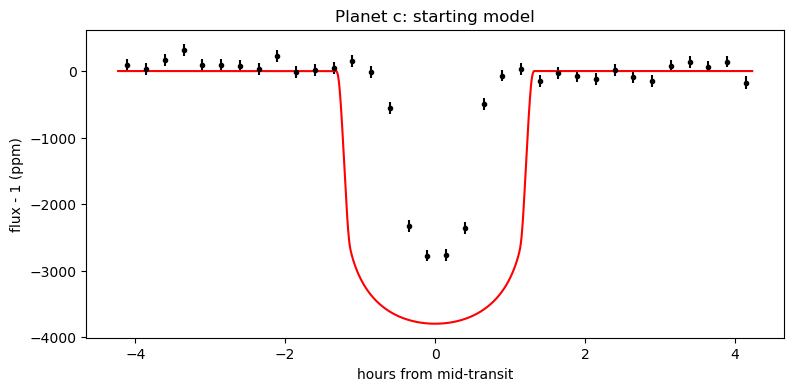

In [22]:
def bin_phase(ph, y, half, width_min=15):
    w = width_min / 1440
    edges = np.arange(-half, half + w, w)
    n, _ = np.histogram(ph, bins=edges)
    s, _ = np.histogram(ph, bins=edges, weights=y)
    c = 0.5 * (edges[1:] + edges[:-1])
    ok = n > 0
    return c[ok], s[ok] / n[ok], np.median(dy) / np.sqrt(n[ok])

ph = ((t - theta0[0] + 0.5 * theta0[1]) % theta0[1]) - 0.5 * theta0[1]
cb, fb, eb = bin_phase(ph, f, half_win)
o = np.argsort(ph)

plt.figure(figsize=(9, 4))
plt.errorbar(cb * 24, (fb - 1) * 1e6, eb * 1e6, fmt="ko", ms=3)
plt.plot(ph[o] * 24, (model(theta0)[o] - 1) * 1e6, "r-")
plt.xlabel("hours from mid-transit"); plt.ylabel("flux - 1 (ppm)")
plt.title(f"Planet {name}: starting model")
plt.show()

#### Sampling Begins

In [23]:
#Step 9: Start the walkers

scales = np.array([1e-3, 1e-5, 0.003, 0.0, 0.3 * RHO[1], 0.05, 0.05, 1e-5, 0.02])
rng = np.random.default_rng(1)
nwalk, ndim = 36, 9

p0 = []
while len(p0) < nwalk:
    cand = theta0 + scales * rng.standard_normal(ndim)
    cand[3] = rng.uniform(0.05, 0.9)                 # start b all over the range
    if np.isfinite(log_prob(cand)):
        p0.append(cand)
p0 = np.array(p0)

In [30]:
#Step 10: Running the emcee, and saving the data in the backend

backend = emcee.backends.HDFBackend(f"../data/chain_{name}.h5")
backend.reset(nwalk, ndim)
sampler = emcee.EnsembleSampler(nwalk, ndim, log_prob, backend=backend)
sampler.run_mcmc(p0, 15000, progress=True)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 15000/15000 [22:42<00:00, 11.01it/s]


State([[ 2.65627945e+03  1.60510909e+01  6.21808380e-02  8.70321423e-01
   9.23005396e+00  9.98959679e-01  3.88348617e-01  1.00004209e+00
   3.16211383e-02]
 [ 2.65627895e+03  1.60511140e+01  5.80713899e-02  9.10801853e-01
   7.79070824e+00  2.17380641e-01  5.86098849e-01  1.00001639e+00
   2.62929614e-02]
 [ 2.65627961e+03  1.60511025e+01  5.97949826e-02  8.96162856e-01
   9.10777816e+00  3.15413739e-01  8.78504878e-01  1.00002248e+00
   1.79094651e-02]
 [ 2.65627892e+03  1.60511008e+01  6.05428751e-02  8.78235597e-01
   9.20396332e+00  7.04952192e-01  4.88348703e-01  1.00004448e+00
   2.70086955e-02]
 [ 2.65627892e+03  1.60511105e+01  5.87294023e-02  9.13787772e-01
   7.79478110e+00  1.80412301e-01  8.85752665e-01  1.00004944e+00
   2.29968969e-02]
 [ 2.65627913e+03  1.60511061e+01  5.28696508e-02  9.23748664e-01
   6.58935125e+00  4.17256076e-03  3.34137066e-02  1.00004525e+00
   3.37861989e-02]
 [ 2.65627938e+03  1.60510982e+01  5.78169836e-02  8.76452382e-01
   1.02673497e+01  4.7

In [31]:
#Step 11: Checking if it converged

tau = sampler.get_autocorr_time(tol=0)
labels = ["T0", "P", "k", "b", "rho", "q1", "q2", "f0", "lns"]
for l, tt in zip(labels, tau):
    print(l, "autocorr time:", round(tt))
print("chain length / longest tau:", round(n_steps / tau.max()))

T0 autocorr time: 179
P autocorr time: 166
k autocorr time: 215
b autocorr time: 197
rho autocorr time: 200
q1 autocorr time: 346
q2 autocorr time: 280
f0 autocorr time: 178
lns autocorr time: 210
chain length / longest tau: 43


In [32]:
#A separate check: This splits the post-burn-in chain in two and compares the medians. 
#If the chain has settled, the halves should agree, with diff / std well below 0.1 to 0.2. 
#A large value means the sampler is still drifting and needs more steps.

burn = int(3 * tau.max())
chain = sampler.get_chain(discard=burn)                 # shape: (steps, walkers, parameters)
mid = chain.shape[0] // 2

for i, l in enumerate(labels):
    h1 = np.median(chain[:mid, :, i])                   # median from the first half
    h2 = np.median(chain[mid:, :, i])                   # median from the second half
    print(l, "| 1st half:", round(h1, 6), "| 2nd half:", round(h2, 6),
          "| diff / std:", round((h1 - h2) / np.std(chain[:, :, i]), 2))

T0 | 1st half: 2656.279406 | 2nd half: 2656.2794 | diff / std: 0.01
P | 1st half: 16.051105 | 2nd half: 16.051105 | diff / std: -0.0
k | 1st half: 0.057214 | 2nd half: 0.05707 | diff / std: 0.03
b | 1st half: 0.899924 | 2nd half: 0.899894 | diff / std: 0.0
rho | 1st half: 8.590358 | 2nd half: 8.576041 | diff / std: 0.01
q1 | 1st half: 0.301521 | 2nd half: 0.289696 | diff / std: 0.06
q2 | 1st half: 0.416067 | 2nd half: 0.423157 | diff / std: -0.02
f0 | 1st half: 1.00003 | 2nd half: 1.00003 | diff / std: 0.0
lns | 1st half: 0.024537 | 2nd half: 0.024505 | diff / std: 0.0


In [33]:
#Rebuilding the chain and saving it

thin = max(1, int(0.5 * tau.min()))
flat = sampler.get_chain(discard=burn, thin=thin, flat=True)
np.save(f"../data/chain_{name}.npy", flat)
print(flat.shape)

(6120, 9)
